# Isolation Forest

Most anomaly detectors first model what "normal" looks like, then flag what doesn't fit. Isolation Forest flips it: **anomalies are few and different, so they are easy to isolate.**

## How it works

1. Build many random trees. Each split picks a **random feature** and a **random cut point** between that feature's min and max — no labels, no distances, no gain criterion.
2. A point in a dense cluster is surrounded by neighbours, so it takes many cuts to get it alone in a leaf (**long path**). A far-off point is alone after a cut or two (**short path**).
3. Average the path length `E[h(x)]` over all trees (a leaf that still holds `m` points is credited `c(m)`, the average depth needed to separate them) and normalize:

   `score(x) = 2^(−E[h(x)] / c(ψ))`

   Near **1** = anomaly, around **0.5** = nothing stands out, well below 0.5 = deep in the crowd.
4. `predict` flags the top `contamination` fraction of training scores as `−1`.

Each tree sees only a random subsample of `ψ = 256` points and is cut off at depth `⌈log₂ ψ⌉`. That keeps it fast (near linear in `n`) and stops dense clusters from hiding anomalies — more data is not better here.

Good for tabular data with numeric features and no labels. It can miss anomalies that sit *inside* a cluster's range, and axis-aligned random cuts struggle when anomalies are only visible as a combination of features. See `40_local_outlier_factor` for a density-based take.

Note: scikit-learn's `score_samples` returns the **negative** of this score (higher = more normal). The demo flips it to compare.

`ponytail:` nested tuples and Python recursion — fine for thousands of points; use flat arrays or sklearn for millions.

## Usage

```python
# (the class is defined in the Implementation section below)

forest = IsolationForest(n_estimators=100, contamination=0.05).fit(X)
forest.score_samples(X)    # in (0, 1), higher = more anomalous
forest.predict(X_new)      # -1 anomaly, 1 normal
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _c(n):
    """Average path length of an unsuccessful search in a binary search tree of n points.
    Used to normalize path lengths and to credit leaves that still hold several points."""
    if n <= 1:
        return 0.0
    if n == 2:
        return 1.0
    return 2.0 * (np.log(n - 1) + 0.5772156649) - 2.0 * (n - 1) / n


def _grow(X, depth, limit, rng):
    """Random tree: pick a random feature, split at a random value between its min and max.
    Returns an int (leaf holding that many points) or (feature, split, left, right)."""
    n = len(X)
    if depth >= limit or n <= 1:
        return n
    features = np.flatnonzero(X.max(axis=0) > X.min(axis=0))
    if len(features) == 0:  # all points identical
        return n
    f = rng.choice(features)
    split = rng.uniform(X[:, f].min(), X[:, f].max())
    left = X[:, f] < split
    return (f, split, _grow(X[left], depth + 1, limit, rng), _grow(X[~left], depth + 1, limit, rng))


def _path_lengths(node, X, idx, depth, out):
    if not isinstance(node, tuple):
        out[idx] = depth + _c(node)
        return
    f, split, left, right = node
    go_left = X[idx, f] < split
    _path_lengths(left, X, idx[go_left], depth + 1, out)
    _path_lengths(right, X, idx[~go_left], depth + 1, out)


class IsolationForest:
    """Anomaly detection by how EASY a point is to isolate.

    Build many random trees: each split picks a random feature and a random cut point. Anomalies are
    few and different, so a handful of random cuts already puts them alone in a leaf -- a SHORT path
    from the root. Normal points sit in dense regions and need many cuts -- a LONG path.

        score(x) = 2 ** (-E[path length of x] / c(psi))        in (0, 1)

    near 1 = anomaly, around 0.5 = nothing stands out, well below 0.5 = deep inside the crowd.
    Each tree is grown on a small random subsample (`max_samples`, default 256), which both makes it
    fast and stops dense clusters from masking the anomalies.

    Note: scikit-learn's `score_samples` returns the NEGATIVE of this score (higher = more normal).

    ponytail: nodes are nested tuples and recursion is plain Python, fine for thousands of points;
    use flat arrays (or sklearn) for big data."""

    def __init__(self, n_estimators=100, max_samples=256, contamination=0.1, random_state=0):
        self.n_estimators = n_estimators
        self.max_samples = max_samples
        self.contamination = contamination
        self.random_state = random_state

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)
        self.psi_ = min(self.max_samples, len(X))
        limit = int(np.ceil(np.log2(max(self.psi_, 2))))  # stop at ~average tree height; anomalies are shallow
        self.trees_ = [
            _grow(X[rng.choice(len(X), self.psi_, replace=False)], 0, limit, rng)
            for _ in range(self.n_estimators)
        ]
        self.threshold_ = np.quantile(self.score_samples(X), 1 - self.contamination)
        return self

    def score_samples(self, X):
        """Anomaly score in (0, 1); higher = more anomalous."""
        X = np.asarray(X, dtype=float)
        total = np.zeros(len(X))
        for tree in self.trees_:
            lengths = np.zeros(len(X))
            _path_lengths(tree, X, np.arange(len(X)), 0, lengths)
            total += lengths
        return 2.0 ** (-(total / self.n_estimators) / _c(self.psi_))

    def predict(self, X):
        """-1 for anomalies (top `contamination` fraction of training scores), 1 for normal."""
        return np.where(self.score_samples(X) > self.threshold_, -1, 1)

    def fit_predict(self, X):
        return self.fit(X).predict(X)

## See it work

### 1. The anomaly score as a landscape

Each cell of the plane gets the score a point there would receive: near 1 (red) means very easy to isolate, near 0.5 or below (blue) means deep in the crowd. The model never saw labels, yet the outliers (black crosses) sit in the red zone.

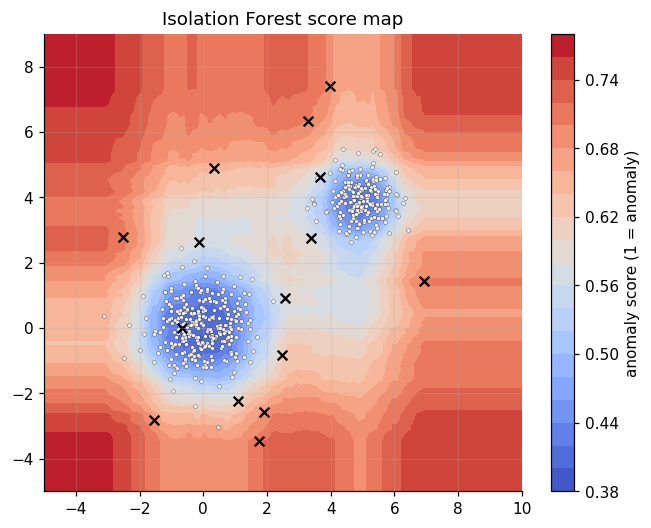

In [3]:
rng = np.random.default_rng(0)
inliers = np.vstack([rng.normal([0, 0], 0.8, size=(300, 2)), rng.normal([5, 4], 0.6, size=(200, 2))])
outliers = rng.uniform(-4, 9, size=(15, 2))
X = np.vstack([inliers, outliers]); is_out = np.array([0] * 500 + [1] * 15)
forest = IsolationForest(n_estimators=100, contamination=0.03, random_state=0).fit(X)
gx, gy = np.meshgrid(np.linspace(-5, 10, 120), np.linspace(-5, 9, 120))
S = forest.score_samples(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
plt.figure(figsize=(7, 5.4))
plt.contourf(gx, gy, S, levels=20, cmap="coolwarm"); plt.colorbar(label="anomaly score (1 = anomaly)")
plt.scatter(*inliers.T, s=6, c="w", edgecolor="k", linewidth=0.2); plt.scatter(*outliers.T, c="k", marker="x", s=40)
plt.title("Isolation Forest score map"); plt.show()

### 2. Scores separate the two groups

Histogram of scores for the real inliers and the planted outliers, with the threshold implied by `contamination`. Points above the threshold are flagged (`−1`). The planted outliers are uniformly random, so some land inside or beside a cluster by chance and cannot be caught: not all 15 are flagged.

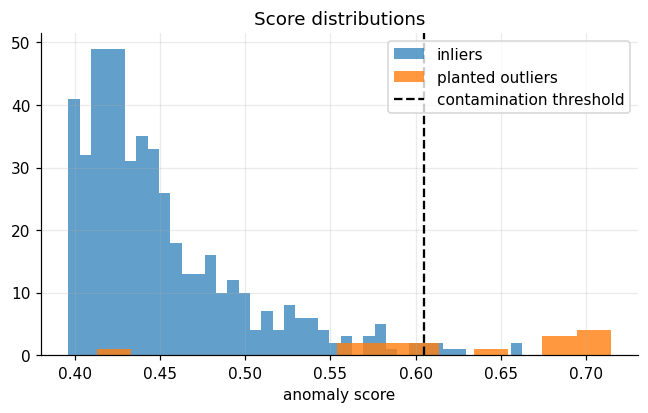

flagged: 16 | of the planted outliers caught: 8 of 15


In [4]:
s = forest.score_samples(X)
plt.figure(figsize=(7, 3.8)); plt.hist(s[is_out == 0], bins=40, alpha=0.7, label="inliers"); plt.hist(s[is_out == 1], bins=15, alpha=0.8, label="planted outliers")
plt.axvline(forest.threshold_, color="k", ls="--", label="contamination threshold"); plt.xlabel("anomaly score"); plt.legend(); plt.title("Score distributions"); plt.show()
pred = forest.predict(X); print("flagged:", (pred == -1).sum(), "| of the planted outliers caught:", ((pred == -1) & (is_out == 1)).sum(), "of", is_out.sum())

### 3. More trees = a more stable score

Each tree is random, so a single tree's score is noisy; averaging many makes the ranking stable. Standard deviation of one point's score across 20 different seeds:

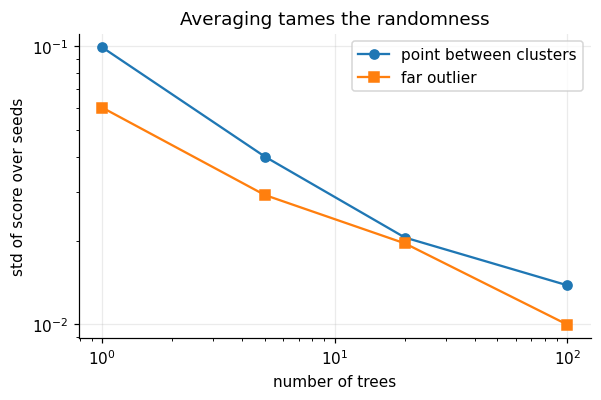

In [5]:
probe = np.array([[2.5, 2.0], [9.0, -4.0]])    # one point between the clusters, one far outlier
ns = [1, 5, 20, 100]
sd = np.array([[IsolationForest(n_estimators=n, random_state=s).fit(X).score_samples(probe) for s in range(20)] for n in ns]).std(axis=1)
plt.figure(figsize=(6, 3.6)); plt.loglog(ns, sd[:, 0], "o-", label="point between clusters"); plt.loglog(ns, sd[:, 1], "s-", label="far outlier")
plt.xlabel("number of trees"); plt.ylabel("std of score over seeds"); plt.legend(); plt.title("Averaging tames the randomness"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from scipy.stats import spearmanr
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest as SklearnIF
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(0)
X_in, _ = make_blobs(n_samples=950, centers=[[0, 0], [6, 6]], cluster_std=1.0, random_state=0)
X_out = rng.uniform(-6, 12, size=(50, 2))
X = np.vstack([X_in, X_out])
is_outlier = np.array([0] * 950 + [1] * 50)   # note: some "outliers" land inside the blobs by chance

ours = IsolationForest(n_estimators=100, contamination=0.05, random_state=0).fit(X)
theirs = SklearnIF(n_estimators=100, contamination=0.05, random_state=0).fit(X)

s_ours = ours.score_samples(X)
s_theirs = -theirs.score_samples(X)   # sklearn returns the negative score
rho = spearmanr(s_ours, s_theirs)[0]
print("ROC AUC at spotting the planted outliers: ours=%.3f sklearn=%.3f" % (roc_auc_score(is_outlier, s_ours), roc_auc_score(is_outlier, s_theirs)))
print("rank correlation of the two scores (different random trees, so not identical): %.3f" % rho)
print("flagged: ours=%d sklearn=%d, agree on %.1f%% of labels" % ((ours.predict(X) == -1).sum(), (theirs.predict(X) == -1).sum(), 100 * (ours.predict(X) == theirs.predict(X)).mean()))
assert rho > 0.9
assert abs(roc_auc_score(is_outlier, s_ours) - roc_auc_score(is_outlier, s_theirs)) < 0.02

ROC AUC at spotting the planted outliers: ours=0.953 sklearn=0.953
rank correlation of the two scores (different random trees, so not identical): 0.952
flagged: ours=50 sklearn=50, agree on 99.6% of labels


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _data(seed=0):
    rng = np.random.default_rng(seed)
    inliers = rng.normal(size=(500, 2))
    outliers = np.sign(rng.normal(size=(15, 2))) * rng.uniform(5, 9, size=(15, 2))
    return np.vstack([inliers, outliers]), np.array([0] * 500 + [1] * 15)


def test_average_path_length_known_values():
    assert _c(1) == 0
    assert _c(2) == 1
    assert np.isclose(_c(256), 2 * (np.log(255) + 0.5772156649) - 2 * 255 / 256)
    assert _c(256) > _c(16) > _c(2)                              # grows like log n


def test_outliers_score_higher_and_are_ranked_first():
    X, is_out = _data()
    model = IsolationForest(random_state=0).fit(X)
    s = model.score_samples(X)
    assert ((s > 0) & (s < 1)).all()
    assert s[is_out == 1].min() > s[is_out == 0].mean()
    assert s[is_out == 1].mean() > 0.6 and s[is_out == 0].mean() < 0.5
    top = np.argsort(s)[::-1][: is_out.sum()]
    assert is_out[top].mean() > 0.9   # top-15 scores are (almost) exactly the 15 planted outliers


def test_predict_flags_contamination_fraction_and_is_reproducible():
    X, _ = _data()
    labels = IsolationForest(contamination=0.05, random_state=3).fit_predict(X)
    assert set(labels) == {-1, 1}
    assert abs((labels == -1).mean() - 0.05) < 0.01
    again = IsolationForest(contamination=0.05, random_state=3).fit_predict(X)
    assert (labels == again).all()


def test_far_new_point_is_an_anomaly_center_point_is_not():
    X, _ = _data()
    model = IsolationForest(random_state=0).fit(X)
    assert model.predict([[0.0, 0.0], [40.0, 40.0]]).tolist() == [1, -1]

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_average_path_length_known_values
PASS test_outliers_score_higher_and_are_ranked_first


PASS test_predict_flags_contamination_fraction_and_is_reproducible
PASS test_far_new_point_is_an_anomaly_center_point_is_not

all 4 tests passed


## Takeaways

- **Use it** as a fast default for unsupervised anomaly detection on tabular data: no distances, near-linear time, handles many features and big `n` (each tree uses only a small subsample).
- **Idea:** random splits isolate anomalies in few cuts; score `2^(−E[h(x)]/c(ψ))`, with path length `h`. Subsampling (`ψ = 256`) is a feature: it keeps the trees shallow and avoids masking.
- **Pitfalls:** axis-aligned cuts miss anomalies visible only through feature combinations; the `contamination` threshold is an assumption; categorical features need encoding. scikit-learn returns the *negative* of this score.
- **Interview line:** *"Anomalies are few and different, so random partitioning isolates them with short paths; the score is a normalised average path length over many random trees."*